# Additional 02 - Retention, clustering and contribution-value scenarios

Supporting customer analytics preserved from the broader portfolio exploration. These calculations are not inputs to the current coupon audience ranking. Run independently; RFM features are rebuilt during setup.

First-observed cohorts are not acquisition cohorts. K-Means IDs are arbitrary. The contribution calculation relies on assumed margin and survival and is not measured lifetime value.

**Step 1: Prepare imports, imports, imports.**

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from IPython.display import display, Markdown

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)


**Step 2: Prepare config, FIGURES.**

In [2]:
if ROOT is None:
    raise RuntimeError("Open inside retail-customer-360")
sys.path.insert(0, str(ROOT / "src"))
config = json.loads((ROOT / "config/project.json").read_text())
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "additional/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
BLUE, TEAL, ORANGE = "#245C83", "#208778", "#D77931"


**Step 3: Define the finish helper.**

In [3]:
from IPython.display import Image as NotebookImage


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 4: Load data and inspect the input.**

In [4]:
from retail_customer_360.metrics import load_transactions
from retail_customer_360.customer_analytics import (
    create_baskets,
    features_at,
    rfm_segments,
    cluster_customers,
    retention_tables,
    contribution_scenario,
)

con = load_transactions(ROOT)
AS_OF_DAY = con.execute("""SELECT max(day)
FROM raw_transactions""").fetchone()[0]
create_baskets(con, AS_OF_DAY)


**Step 5: Prepare features, rfm.**

In [5]:
print("Cutoff source day:", AS_OF_DAY)
display(config)

features = features_at(con, AS_OF_DAY)
rfm = rfm_segments(features)


Cutoff source day: 711


{'seed': 42,
 'lookback_days': 180,
 'horizon_days': 30,
 'clv_scenario': {'months': 6,
  'gross_margin': 0.25,
  'monthly_survival': 0.9,
  'annual_discount_rate': 0.1},
 'crm': {'budget_usd': 250,
  'discount_usd': 2,
  'contact_cost_usd': 0.05,
  'assumed_absolute_uplift': 0.1,
  'gross_margin': 0.25,
  'exclude_baseline_purchase_above': 0.8,
  'minimum_observed_history_days': 30},
 'model': {'selection_metric': 'validation_average_precision',
  'random_forest_trees': 200}}

In [6]:
display(features.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2


In [7]:
display(rfm.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,r_score,f_score,m_score,segment
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,3,4,4,Loyal
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,1,2,3,Occasional
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,3,1,2,Occasional
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,1,1,1,Occasional
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,3,2,1,Occasional


## 2. First-observed cohorts and repeat-period retention

Periods are 30 source days anchored at day 1, not calendar months. Cohort membership is first observed paid purchase, not acquisition. Numerator: distinct cohort households purchasing in a period; denominator: the original cohort size. Return visits can make later-period retention rise. Incomplete periods are blank, not zero. Early cohorts are left-censored and contain pre-existing shoppers.

**Step 6: Check the calculation.**

In [8]:
cohorts, retention = retention_tables(con, AS_OF_DAY)
assert cohorts.loc[~cohorts.observation_complete, "retention_rate"].isna().all()
display(cohorts.head(15))
display(retention)
pivot = cohorts.pivot(
    index="cohort_start_day", columns="period_age", values="retention_rate"
)
fig = Figure(figsize=(12, 7))
ax = fig.subplots()
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#eeeeee")
image = ax.imshow(
    np.ma.masked_invalid(pivot.to_numpy()), aspect="auto", vmin=0, vmax=1, cmap=cmap
)
ax.set_xticks(range(len(pivot.columns)), pivot.columns)


,cohort_period,cohort_start_day,cohort_size,period,period_age,period_end_day,observation_complete,active_households,retention_rate
0,0,1,527,0,0,30,True,527,1.000000
1,0,1,527,1,1,60,True,427,0.810247
2,0,1,527,2,2,90,True,420,0.796964
3,0,1,527,3,3,120,True,414,0.785579
4,0,1,527,4,4,150,True,415,0.787476
5,0,1,527,5,5,180,True,420,0.796964
6,0,1,527,6,6,210,True,422,0.800759
7,0,1,527,7,7,240,True,422,0.800759
8,0,1,527,8,8,270,True,426,0.808349
9,0,1,527,9,9,300,True,428,0.812144


,period,period_start_day,previous_active_households,current_active_households,retained_households,retention_rate
0,1,31,527,972,427,0.810247
1,2,61,972,1552,822,0.845679
2,3,91,1552,2141,1315,0.847294
3,4,121,2141,1996,1835,0.857076
4,5,151,1996,1997,1778,0.890782
5,6,181,1997,1979,1789,0.895844
6,7,211,1979,1987,1792,0.905508
7,8,241,1987,2006,1786,0.898842
8,9,271,2006,2018,1816,0.905284
9,10,301,2018,1988,1811,0.897423


**Show cohort sizes.** Each label includes the original number of households. An asterisk marks a small cohort with fewer than 10 households; its rate can change sharply when one household does not purchase.

In [9]:
cohort_sizes = (
    cohorts[["cohort_start_day", "cohort_size"]]
    .drop_duplicates()
    .set_index("cohort_start_day")["cohort_size"]
    .reindex(pivot.index)
)
cohort_labels = [
    f"Day {day} | n={int(size):,}" + (" *" if size < 10 else "")
    for day, size in cohort_sizes.items()
]
ax.set_yticks(range(len(pivot.index)), cohort_labels)
assert cohort_sizes.notna().all()


**Step 7: Finish and display the chart.**

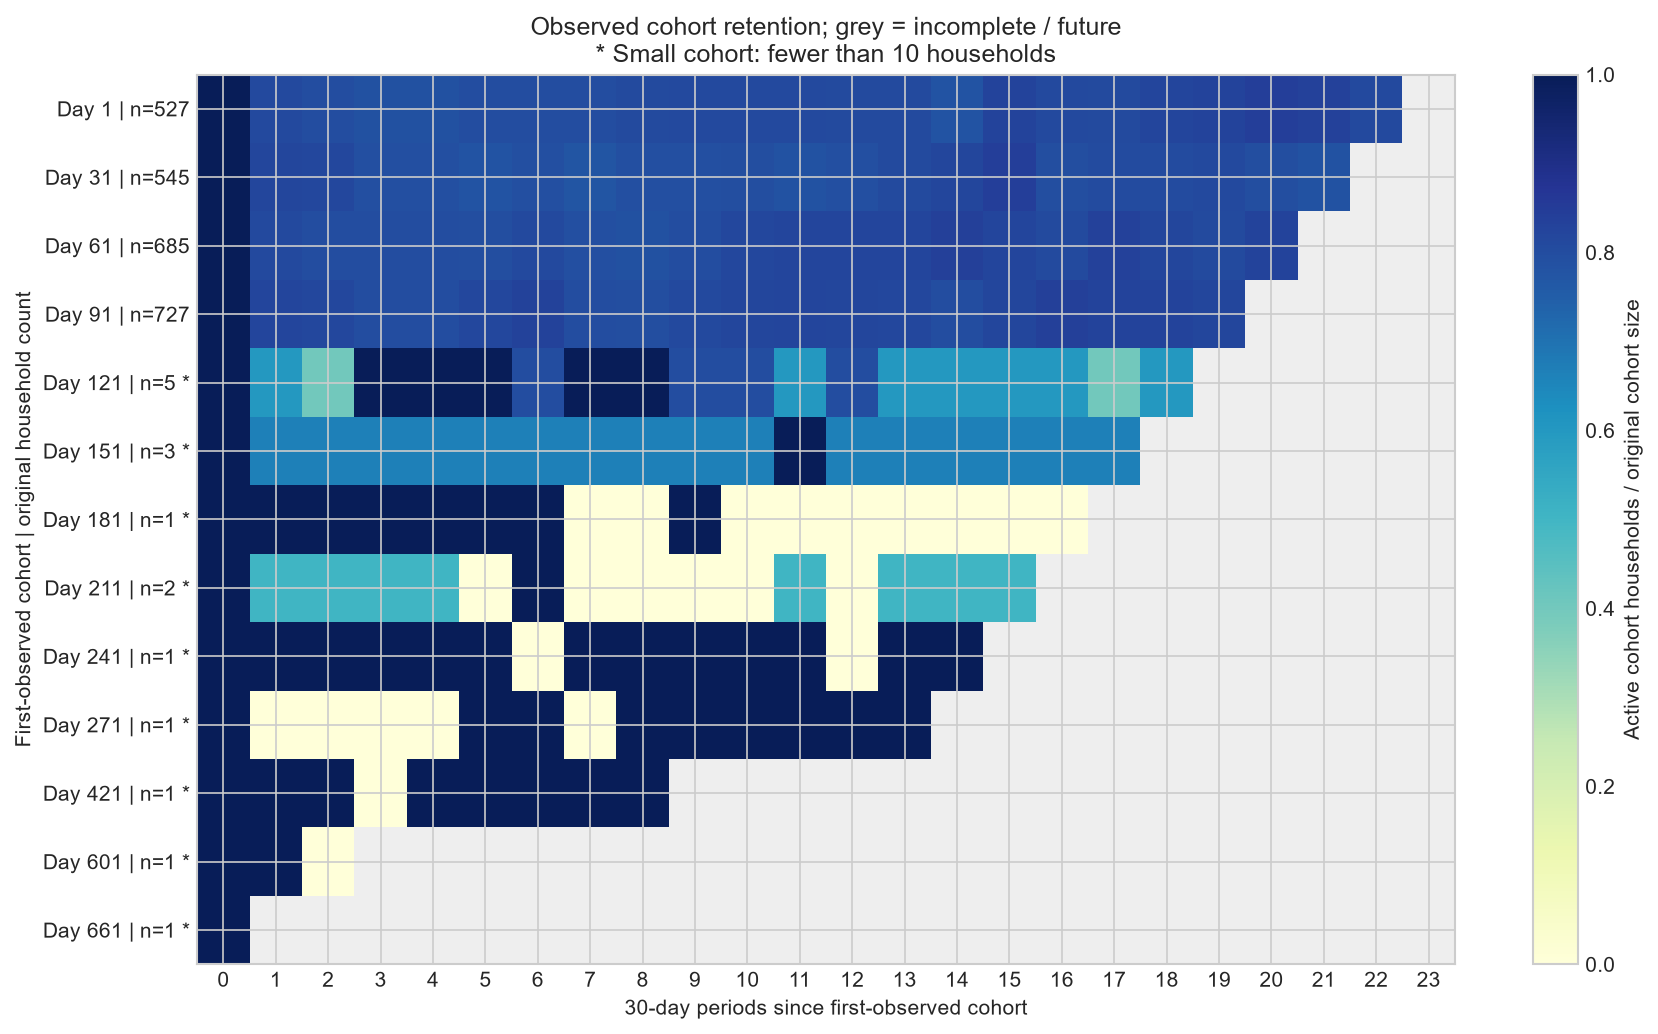

In [10]:
ax.set(
    xlabel="30-day periods since first-observed cohort",
    ylabel="First-observed cohort | original household count",
    title=(
        "Observed cohort retention; grey = incomplete / future\n"
        "* Small cohort: fewer than 10 households"
    ),
)
fig.colorbar(image, ax=ax, label="Active cohort households / original cohort size")
finish(fig, "04_cohort_retention.png")
fig = Figure(figsize=(11, 4))
ax = fig.subplots()
ax.plot(
    retention.period_start_day, 100 * retention.retention_rate, color=BLUE, marker="o"
)


**Step 8: Finish and display the chart.**

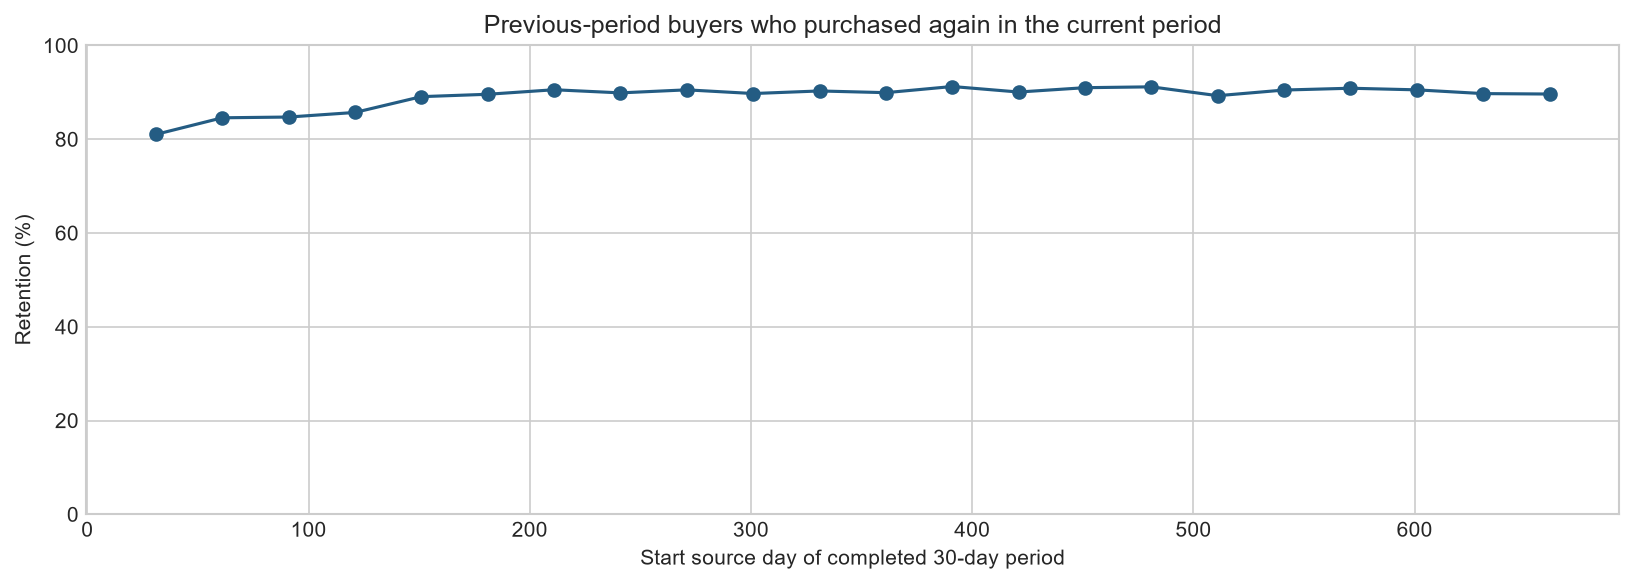

In [11]:
ax.set(
    xlabel="Start source day of completed 30-day period",
    ylabel="Retention (%)",
    ylim=(0, 100),
    title="Previous-period buyers who purchased again in the current period",
)
finish(fig, "04_period_retention.png")


## 3. K-Means: compare K and inspect original-scale profiles

Fit StandardScaler to log1p(recency, frequency, monetary) for currently active households. Compare K=2..6 using silhouette, then check seed stability with adjusted Rand index. Cluster IDs are arbitrary. An inactive household receives -1 rather than an invented active cluster. No cluster is called VIP solely because its numeric ID is high.

The figure is assembled across short cells and displayed only when both panels are complete. The right panel contains one point per active household, coloured by cluster.

**Step 9: Build the chart.**

In [12]:
assignments, k_scores, cluster_profile, cluster_meta, cluster_artifact = (
    cluster_customers(rfm, config["seed"])
)
display(k_scores)
display(cluster_profile)
display(cluster_meta)
clustered = rfm.merge(assignments, on="household_key", validate="one_to_one")
fig = Figure(figsize=(12, 4.5))
axes = fig.subplots(1, 2)
axes[0].plot(k_scores.k, k_scores.silhouette, marker="o", color=BLUE)
axes[0].set(
    xlabel="K", ylabel="Silhouette score", title="Exploratory cluster separation"
)
active = clustered.loc[clustered.cluster >= 0]

assert not active.empty, "No active households to plot."


,k,silhouette,inertia
0,2,0.446513,3428.199246
1,3,0.359018,2398.536156
2,4,0.341918,1951.284191
3,5,0.312135,1629.473854
4,6,0.285020,1452.583376


,cluster,households,median_recency,median_frequency_180,median_monetary_180
0,0,1536,2.0,34.0,1076.005
1,1,894,24.0,7.0,173.950


{'chosen_k': 2, 'seed_stability_adjusted_rand': 1.0}

**Step 10: Build the chart.**

In [13]:
for label, frame in active.groupby("cluster"):
    axes[1].scatter(
        frame.frequency_180,
        frame.monetary_180,
        s=12,
        alpha=0.45,
        label=f"Cluster {label}",
    )
axes[1].set(
    xscale="log",
    yscale="log",
    xlabel="180-day paid baskets (log)",
    ylabel="180-day sales, USD (log)",
    title="Clusters on original feature axes",
)
axes[1].legend(frameon=False)


**Step 11: Finish and display the chart.**

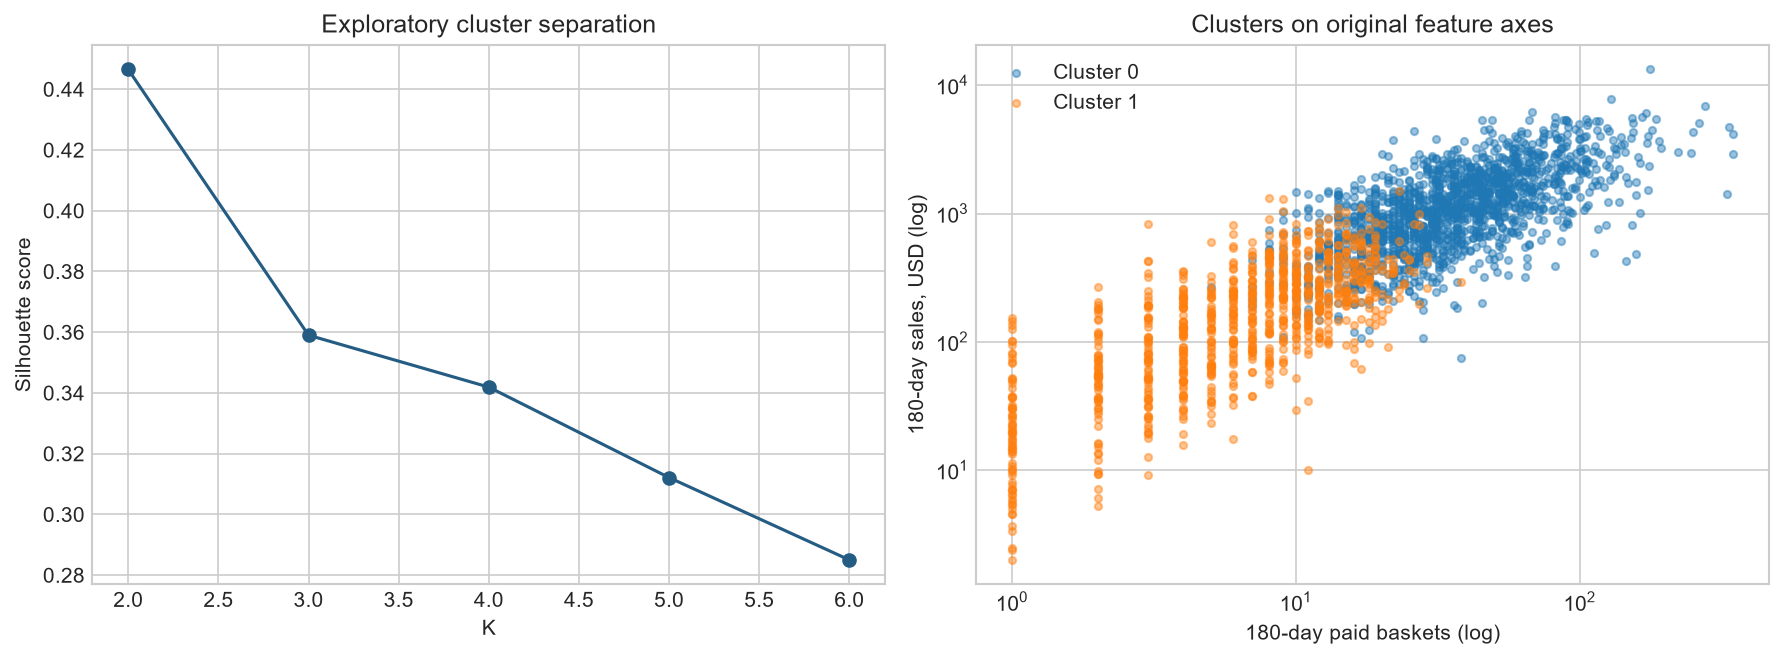

cluster,-1,0,1
segment,,,
At risk,0,8,29
Champions,0,531,0
Hibernating,70,0,97
Loyal,0,323,0
Occasional,0,564,713
Potential loyalists,0,110,55


In [14]:
assert len(axes[1].collections) == active.cluster.nunique()
finish(fig, "04_kmeans_diagnostics.png")
display(pd.crosstab(clustered.segment, clustered.cluster))


## 4. CLV-style contribution scenario, not a lifetime estimate

Use historical 180-day sales / 6 as a stationary monthly sales run-rate. For months 1..6, multiply by assumed margin and survival^month and discount to present value. Margin and survival are assumptions, not inferred from purchase retention. No cost-of-goods data or customer lifetime is observed. New/seasonal customers and return behaviour can violate the stationary run-rate assumption.

**Step 12: Build the chart.**

In [15]:
value = contribution_scenario(rfm, **config["clv_scenario"])
display(config["clv_scenario"])
display(value.head(10))
scenario_rows = []
for survival in [0.8, 0.9, 1.0]:
    v = contribution_scenario(
        rfm, **{**config["clv_scenario"], "monthly_survival": survival}
    )
    scenario_rows.append({
        "assumed_monthly_survival": survival,
        "total_scenario_contribution_usd": v.scenario_contribution_usd.sum(),
    })
display(pd.DataFrame(scenario_rows))
fig = Figure(figsize=(10, 4.5))
ax = fig.subplots()
ax.hist(value.scenario_contribution_usd, bins=45, color=TEAL, edgecolor="white")


{'months': 6,
 'gross_margin': 0.25,
 'monthly_survival': 0.9,
 'annual_discount_rate': 0.1}

,household_key,monetary_180,scenario_contribution_usd,horizon_months,assumed_gross_margin,assumed_monthly_survival
0,1,1310.41,224.502822,6,0.25,0.9
1,2,569.10,97.499680,6,0.25,0.9
2,3,236.30,40.483526,6,0.25,0.9
3,4,141.93,24.315814,6,0.25,0.9
4,5,128.34,21.987540,6,0.25,0.9
5,6,1376.35,235.799833,6,0.25,0.9
6,7,1471.86,252.162852,6,0.25,0.9
7,8,1885.88,323.093827,6,0.25,0.9
8,9,272.06,46.610021,6,0.25,0.9
9,10,70.40,12.061110,6,0.25,0.9


,assumed_monthly_survival,total_scenario_contribution_usd
0,0.8,278193.549537
1,0.9,396459.521589
2,1.0,562718.692537


(array([804., 449., 306., 250., 176., 127.,  91.,  82.,  48.,  44.,  28.,
         18.,  14.,  14.,  13.,   8.,   5.,   7.,   9.,   2.,   2.,   0.,
          0.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([   0.        ,   50.53030051,  101.06060103,  151.59090154,
         202.12120205,  252.65150257,  303.18180308,  353.71210359,
         404.24240411,  454.77270462,  505.30300513,  555.83330565,
         606.36360616,  656.89390667,  707.42420719,  757.9545077 ,
         808.48480821,  859.01510873,  909.54540924,  960.07570975,
        1010.60601027, 1061.13631078, 1111.66661129, 1162.19691181,
        1212.72721232, 1263.25751283, 1313.78781335, 1364.31811386,
        1414.84841437, 1465.37871489, 1515.9090154 , 1566.43931591,
        1616.96961643, 1667.49991694, 1718.03021745, 1768.56051796,
        1819.09081848, 1869.62111899, 1920.1514195 , 1970.68172002,
        

**Step 13: Finish and display the chart.**

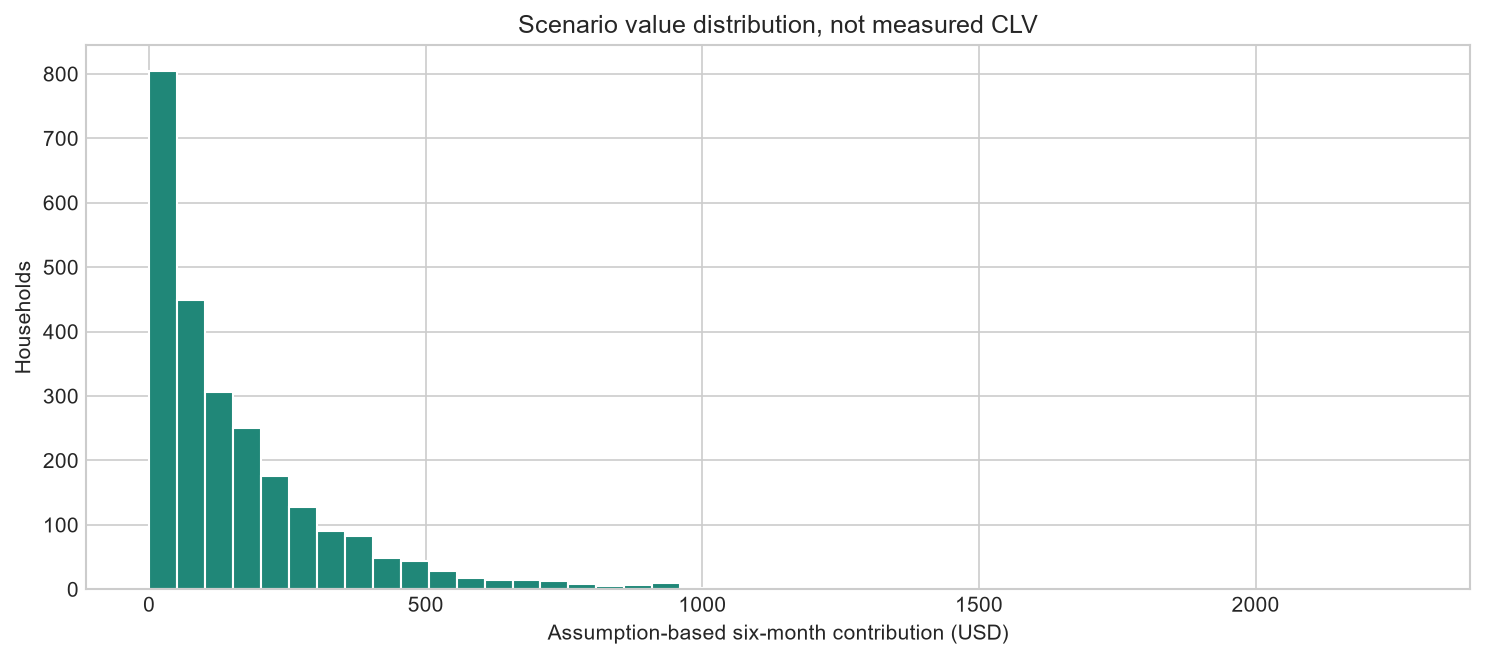

In [16]:
ax.set(
    xlabel="Assumption-based six-month contribution (USD)",
    ylabel="Households",
    title="Scenario value distribution, not measured CLV",
)
finish(fig, "04_contribution_scenario.png")
con.close()


## Scope

These results provide context and optional portfolio depth. The main coupon decision still requires household-category preferences, a valid coupon catalogue, household-coupon candidates and evaluation. None of the optional plots establishes causal offer response.